# FRED-MD period and intercept CV exploration

This notebook reports the completed 352-surface sensitivity experiment for
WERM on FRED-MD. It compares the DPDU window, the requested 1970--2024
McScan-style window, the latest official vintage, and the original full
1960--2024 sample. Every dataset is run with and without a constant column.

The corrected loss contract is fixed throughout:

- the base loss (least squares or Huber) is used for segmentation;
- the same base loss is used for every hard within-segment coefficient refit;
- absolute loss is used **only** on held-out observations for CV scoring;
- when a constant column is present, it is excluded from L1/L2 penalties;
- `Lmax=5` means candidates of 1--5 segments, hence 0--4 change points.

The full numerical output is checkpointed under
`results/FRED-MD_period-intercept-CV/`. Re-running the expensive search is
optional; this report reads those completed artifacts.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
RESULT_DIR = ROOT / "results" / "FRED-MD_period-intercept-CV"
with (RESULT_DIR / "summary.json").open() as handle:
    summary = json.load(handle)

all_results = pd.read_csv(RESULT_DIR / "all_selections.csv")
nonzero = pd.read_csv(RESULT_DIR / "nonzero_selections.csv")
target = pd.read_csv(RESULT_DIR / "two_or_three_change_points.csv")
joint_epsilon = pd.read_csv(
    RESULT_DIR / "joint_unpenalized_huber_epsilon_selections.csv"
)
HIGH_DELTA_DIR = (
    ROOT / "results" / "FRED-MD_high-delta-unpenalized-CV-vs-elbow"
)
high_delta = pd.read_csv(HIGH_DELTA_DIR / "all_selections.csv")
high_delta_joint = pd.read_csv(
    HIGH_DELTA_DIR / "joint_huber_epsilon_selections.csv"
)
LOCAL_DELTA_DIR = (
    ROOT / "results" / "FRED-MD_original-Huber-L1-local-delta-elbow"
)
local_delta = pd.read_csv(LOCAL_DELTA_DIR / "selections.csv")

assert len(summary["records"]) == 352
assert len(all_results) == 352
print({
    "completed_surfaces": len(all_results),
    "nonzero_selections": len(nonzero),
    "two_or_three_cp_selections": len(target),
    "max_parallel_jobs": summary["grid"]["n_jobs"],
})

{'completed_surfaces': 352, 'nonzero_selections': 65, 'two_or_three_cp_selections': 22, 'max_parallel_jobs': 36}


## Data and reference-protocol audit

The historical pickle is the bundled McScan-prepared design: FRED
transformation codes, per-series standardization, 99.9% truncation, and six
principal components plus the idiosyncratic components. The Python
reproduction in `scripts/fredmd_preprocessing.py` was checked against it to
machine precision (up to arbitrary PCA signs).

The latest-vintage design uses the same pipeline on the official July 2026
FRED-MD download. Its last usable predictor month is May 2026 because the
design predicts next-month industrial production. Exact comparisons across
vintages are not pure endpoint comparisons: revisions and the balanced
feature set also change (114 historical predictors versus 92 latest-vintage
predictors).

There is also an important naming distinction: the requested “McScan period”
below is 1970-01--2024-01. The bundled McScan paper's final real-data analysis
actually uses 1960-01--2024-05, included here as the audit dataset.

In [2]:
dataset_rows = []
for name, values in summary["datasets"].items():
    dataset_rows.append({"dataset": name, **values})
datasets = pd.DataFrame(dataset_rows)
display(datasets[["dataset", "start", "end", "n", "p"]])
display(pd.Series(summary["official_vintage"], name="latest-vintage metadata"))

,dataset,start,end,n,p
0,DPDU_2000-01_to_2022-12,2000-01,2022-12,276,114
1,McScan_requested_1970-01_to_2024-01,1970-01,2024-01,649,114
2,Our_latest_1970-01_to_2026-05,1970-01,2026-05,677,92
3,Prior_full_sample_1960-01_to_2024-05,1960-01,2024-05,773,114


label                                                                    2026-07
source_url                     https://www.stlouisfed.org/-/media/project/frb...
raw_latest_row                                                           2026-06
one_step_design_latest_date                                              2026-05
Name: latest-vintage metadata, dtype: object

## Search grid

For each dataset/intercept pair, the search covers two and five interlaced
folds, minimum segment fractions `n/50` and `n/30`, unpenalized least
squares, unpenalized Huber with epsilon in
`{0.5, 0.75, 1, 1.35, 2, 3}`, and L1/L2-penalized least squares or
Huber (`epsilon=1.35`) with constants
`{0.15, 0.3, 0.5, 0.75, 1, 2}`. Coefficient constants and the segment count
are selected jointly for penalized fits. An additional summary selects
epsilon and segment count jointly for unpenalized Huber.

In [3]:
display(pd.Series(summary["loss_contract"], name="CV contract"))
display(pd.Series({
    "coefficient constants": summary["grid"]["constants"],
    "segment counts": summary["grid"]["segment_counts"],
    "Huber epsilons": summary["grid"]["unpenalized_huber_epsilons"],
    "sensitivities": summary["grid"]["sensitivities"],
}, name="values"))

segmentation                                                    base loss
hard_segment_refits                                        same base loss
heldout_scoring_only                                        absolute_loss
coefficient_penalty                            none, L1, or L2 as labeled
intercept               leading ones column when enabled; excluded fro...
Name: CV contract, dtype: object

coefficient constants                     [0.15, 0.3, 0.5, 0.75, 1.0, 2.0]
segment counts                                             [1, 2, 3, 4, 5]
Huber epsilons                            [0.5, 0.75, 1.0, 1.35, 2.0, 3.0]
sensitivities            [{'num_folds': 2, 'delta_fraction': 0.02}, {'n...
Name: values, dtype: object

## Overall selection behavior

The full grid contains many zero selections, especially with five folds.
This makes fold sensitivity part of the scientific result rather than a
nuisance to hide. The table and plot below expose the complete count
distribution by dataset and intercept choice.

0 CP  1 CP  2 CP  3 CP  4 CP
dataset                              intercept                              
DPDU_2000-01_to_2022-12              False        21     7     9     0     7
                                     True         23    10     4     2     5
McScan_requested_1970-01_to_2024-01  False        40     4     0     0     0
                                     True         40     3     0     0     1
Our_latest_1970-01_to_2026-05        False        42     0     2     0     0
                                     True         40     0     3     1     0
Prior_full_sample_1960-01_to_2024-05 False        41     2     0     1     0
                                     True         40     4     0     0     0

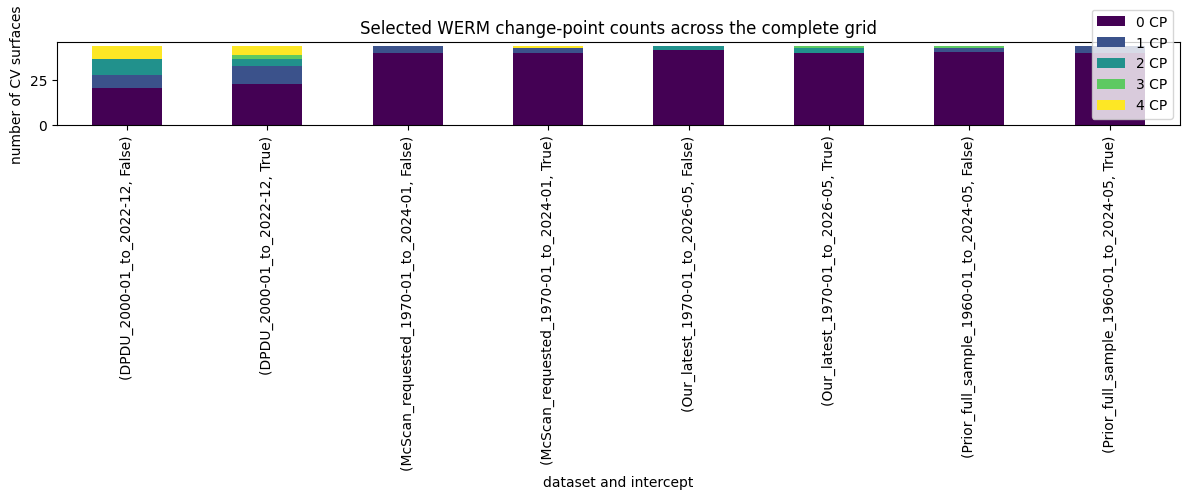

In [4]:
count_table = (
    all_results.groupby(["dataset", "intercept", "selected_change_points"])
    .size().unstack(fill_value=0).reindex(columns=range(5), fill_value=0)
)
count_table.columns = [f"{value} CP" for value in count_table.columns]
display(count_table)

count_table.plot(kind="bar", stacked=True, figsize=(12, 5), colormap="viridis")
plt.ylabel("number of CV surfaces")
plt.xlabel("dataset and intercept")
plt.title("Selected WERM change-point counts across the complete grid")
plt.tight_layout()
plt.show()

## Every 2- or 3-change-point candidate

These are all 22 target-count selections, without filtering on location.
`cv_mae` is the held-out absolute-error score. The improvement column compares
the selected result with the best zero-change-point candidate on the same
loss/penalty/fold/delta surface. A positive but small margin should be treated
as fragile.

In [5]:
target_display = target.copy()
target_display["delta"] = target_display["delta_fraction"].map(
    lambda value: "n/50" if np.isclose(value, 1/50) else "n/30"
)
target_display["cv_mae"] = target_display["cv_mae"].round(6)
target_display["zero_cp_cv_mae"] = target_display["zero_cp_cv_mae"].round(6)
target_display["improvement_vs_zero_pct"] = target_display[
    "improvement_vs_zero_pct"
].round(3)
display(target_display[[
    "dataset", "intercept", "loss", "penalty", "folds", "delta",
    "selected_constant", "selected_change_points", "estimated_dates",
    "cv_mae", "zero_cp_cv_mae", "improvement_vs_zero_pct",
]].reset_index(drop=True))

,dataset,intercept,loss,penalty,folds,delta,selected_constant,selected_change_points,estimated_dates,cv_mae,zero_cp_cv_mae,improvement_vs_zero_pct
0,DPDU_2000-01_to_2022-12,False,least-squares,l1,2,n/50,1.00,2,2005-09;2015-11,0.558574,0.561048,0.441
1,DPDU_2000-01_to_2022-12,False,least-squares,l1,2,n/30,1.00,2,2005-09;2015-11,0.558574,0.561048,0.441
2,DPDU_2000-01_to_2022-12,False,Huber-eps0.75,none,2,n/50,0.00,2,2009-02;2014-12,1.265948,1.328208,4.687
3,DPDU_2000-01_to_2022-12,False,Huber-eps0.75,none,2,n/30,0.00,2,2009-02;2014-12,1.275214,1.328208,3.990
4,DPDU_2000-01_to_2022-12,False,Huber-eps1,none,2,n/50,0.00,2,2009-02;2014-12,1.262012,1.301009,2.997
5,DPDU_2000-01_to_2022-12,False,Huber-eps1,none,2,n/30,0.00,2,2009-02;2014-12,1.274532,1.301009,2.035
6,DPDU_2000-01_to_2022-12,False,Huber-eps2,none,2,n/50,0.00,2,2009-02;2014-12,1.249542,1.331194,6.134
7,DPDU_2000-01_to_2022-12,False,Huber-eps2,none,2,n/30,0.00,2,2009-02;2014-12,1.260386,1.331194,5.319
8,DPDU_2000-01_to_2022-12,False,Huber-eps3,none,2,n/30,0.00,2,2009-02;2014-12,1.260415,1.360807,7.377
9,DPDU_2000-01_to_2022-12,True,Huber-eps0.5,none,2,n/50,0.00,2,2009-02;2015-05,1.272788,1.333283,4.537


## Best defensible candidates

The most useful result is in the latest-vintage 1970--2026 sample. With a
properly unpenalized intercept, two-fold LS-L1 selects two changes under both
spacing choices with a 2.59% margin. Huber-L1 also selects two changes at
`n/50`, and its later date (2010-11) is closer to McScan's 2010-05 estimate.
Without an intercept, Huber-L1 is exactly stable across both spacings and its
later date is 2009-06, closer to the DPDU financial-crisis change.

None of those current-vintage candidates survives the switch to five folds;
five-fold CV chooses zero. Thus the honest conclusion is that WERM-CV can
select two or three changes, but the evidence is sensitive to the validation
split rather than uniformly stable.

In [6]:
preferred_mask = (
    target["dataset"].eq("Our_latest_1970-01_to_2026-05")
    & (
        (target["loss"].eq("least-squares") & target["penalty"].eq("l1"))
        | (target["loss"].eq("Huber-eps1.35") & target["penalty"].eq("l1"))
    )
)
preferred = target.loc[preferred_mask].sort_values(
    ["intercept", "loss", "delta_fraction"]
)
display(preferred.reset_index(drop=True))

,dataset,intercept,loss,penalty,folds,delta_fraction,selected_constant,selected_change_points,estimated_dates,cv_mae,zero_cp_cv_mae,improvement_vs_zero_pct
0,Our_latest_1970-01_to_2026-05,False,Huber-eps1.35,l1,2,0.020000,0.30,2,1997-05;2009-06,0.511021,0.522553,2.206834
1,Our_latest_1970-01_to_2026-05,False,Huber-eps1.35,l1,2,0.033333,0.30,2,1997-05;2009-06,0.511021,0.522553,2.206834
2,Our_latest_1970-01_to_2026-05,True,Huber-eps1.35,l1,2,0.020000,0.30,2,1996-03;2010-11,0.510126,0.522769,2.418500
3,Our_latest_1970-01_to_2026-05,True,Huber-eps1.35,l1,2,0.033333,0.30,3,1991-03;1996-09;2015-04,0.514665,0.522769,1.550152
4,Our_latest_1970-01_to_2026-05,True,least-squares,l1,2,0.020000,0.75,2,1996-03;2015-03,0.513400,0.527070,2.593636
5,Our_latest_1970-01_to_2026-05,True,least-squares,l1,2,0.033333,0.75,2,1996-03;2015-01,0.513400,0.527070,2.593636


## Joint unpenalized Huber epsilon and count

Sweeping epsilon is sensible only if it is treated as another tuning
parameter and selected inside the same CV comparison. On the latest and
McScan-style long samples, joint unpenalized Huber always selects zero. On the
shorter DPDU window it selects four changes with two folds and zero with five
folds. Individual fixed-epsilon surfaces can select two or three changes, but
they are not the joint epsilon/count winners and should not be reported as if
they were.

In [7]:
joint_display = joint_epsilon.copy()
joint_display["delta"] = joint_display["delta_fraction"].map(
    lambda value: "n/50" if np.isclose(value, 1/50) else "n/30"
)
display(joint_display[[
    "dataset", "intercept", "folds", "delta", "selected_epsilon",
    "selected_change_points", "estimated_dates", "cv_mae",
    "improvement_vs_epsilon_specific_zero_pct",
]].reset_index(drop=True))

,dataset,intercept,folds,delta,selected_epsilon,selected_change_points,estimated_dates,cv_mae,improvement_vs_epsilon_specific_zero_pct
0,DPDU_2000-01_to_2022-12,False,2,n/50,3.00,4,2004-09;2009-02;2014-11;2017-12,1.248968,8.218562
1,DPDU_2000-01_to_2022-12,False,2,n/30,0.50,4,2005-06;2009-02;2014-11;2017-05,1.250085,0.357170
2,DPDU_2000-01_to_2022-12,False,5,n/50,0.50,0,NaN,0.720258,0.000000
3,DPDU_2000-01_to_2022-12,False,5,n/30,0.50,0,NaN,0.720258,0.000000
4,DPDU_2000-01_to_2022-12,True,2,n/50,0.75,4,2005-06;2009-02;2014-11;2017-09,1.253002,4.584269
5,DPDU_2000-01_to_2022-12,True,2,n/30,0.50,4,2005-06;2009-02;2014-11;2017-06,1.204124,9.687283
6,DPDU_2000-01_to_2022-12,True,5,n/50,0.50,0,NaN,0.717904,0.000000
7,DPDU_2000-01_to_2022-12,True,5,n/30,0.50,0,NaN,0.717904,0.000000
8,McScan_requested_1970-01_to_2024-01,False,2,n/50,0.75,0,NaN,0.582633,0.000000
9,McScan_requested_1970-01_to_2024-01,False,2,n/30,0.75,0,NaN,0.582633,0.000000


## Comparison with published dates and practical recommendation

Reference dates used for interpretation:

- McScan final analysis: 1974-02, 2010-05, 2019-05.
- DPDU 2000--2022 analysis: 2008-06 and 2020-01.

Recommended primary WERM sensitivity: latest official vintage, leading
unpenalized intercept, Huber loss with epsilon 1.35, L1 constant selected from
the stated grid, two interlaced folds, `Delta=n/50`, and 0--4 candidate change
points. It selects two changes at **1996-03 and 2010-11**, with a 2.42% CV-MAE
improvement over zero changes. The 2010 date is comparable to McScan's
2010-05 finding; the earlier date is not a close published match.

As a count-stability sensitivity, latest-vintage LS-L1 with an intercept
selects two changes for both `n/50` and `n/30` (1996-03 and approximately
2015), with a 2.59% margin. Huber-L1 without an intercept also selects two for
both spacings (1997-05 and 2009-06), with a 2.21% margin. These alternatives
support the count but show location sensitivity.

Avoid choosing epsilon, folds, or spacing solely because a desired count
appears. Pre-specify the primary configuration and disclose the five-fold zero
result. A larger independent forecast period or repeated blocked/interlaced
splits would be the strongest next robustness check.

In [8]:
# Compact machine-checkable recommendation record.
recommendation = target.loc[
    target["dataset"].eq("Our_latest_1970-01_to_2026-05")
    & target["intercept"].eq(True)
    & target["loss"].eq("Huber-eps1.35")
    & target["penalty"].eq("l1")
    & target["folds"].eq(2)
    & np.isclose(target["delta_fraction"], 1/50)
].iloc[0]
display(recommendation.to_frame("recommended WERM-CV setting"))

,recommended WERM-CV setting
dataset,Our_latest_1970-01_to_2026-05
intercept,True
loss,Huber-eps1.35
penalty,l1
folds,2
delta_fraction,0.02
selected_constant,0.3
selected_change_points,2
estimated_dates,1996-03;2010-11
cv_mae,0.510126


## Higher minimum-spacing comparison: CV versus the existing elbow

A second completed experiment applies unpenalized least squares and all six
Huber constants to the three requested period variants with
`Delta` in `{n/20, n/10, n/5}`. It reproduces the original notebook's
fold-independent GOF elbow rule exactly.

Out of 252 surfaces, CV selects a nonzero count in 42. Every one is on the
DPDU sample with two folds; all five-fold and both long-sample selections are
zero. The elbow is nonzero for those 42 DPDU cases, but there are **no exact
count matches**: CV chooses three or four changes while the elbow chooses two.
`n/5` is the closest internal agreement because every two-fold DPDU CV fit
chooses three changes versus the elbow's two, with the smallest location
Hausdorff discrepancies around 29 months.

This is not a strong published-date match. On the DPDU sample, `n/5` is about
55 months, so a January 2020 change cannot be selected: only about 36 months
remain before December 2022. Thus the apparently cleaner `n/5` agreement is
partly imposed by an overly restrictive endpoint constraint.

In [9]:
high_delta_overview = high_delta.groupby("dataset").agg(
    surfaces=("key", "size"),
    cv_nonzero=("cv_selected_change_points", lambda values: (values > 0).sum()),
    both_nonzero=("both_nonzero", "sum"),
    exact_nonzero_count_matches=(
        "count_match",
        lambda values: (
            values & high_delta.loc[values.index, "both_nonzero"]
        ).sum(),
    ),
)
display(high_delta_overview)

dpdu_nonzero = high_delta.loc[
    high_delta["dataset"].eq("DPDU_2000-01_to_2022-12")
    & high_delta["both_nonzero"]
]
pattern = dpdu_nonzero.groupby(
    ["folds", "delta_fraction", "intercept"]
).agg(
    settings=("key", "size"),
    cv_counts=("cv_selected_change_points", lambda x: sorted(set(x))),
    elbow_counts=("elbow_selected_change_points", lambda x: sorted(set(x))),
    best_cv_gain_pct=("cv_improvement_vs_zero_pct", "max"),
    minimum_hausdorff_months=("location_hausdorff_months", "min"),
)
display(pattern)

,surfaces,cv_nonzero,both_nonzero,exact_nonzero_count_matches
dataset,,,,
DPDU_2000-01_to_2022-12,84,42,42,0
McScan_requested_1970-01_to_2024-01,84,0,0,0
Our_latest_1970-01_to_2026-05,84,0,0,0


settings cv_counts elbow_counts  \
folds delta_fraction intercept                                    
2     0.05           False             7       [4]          [2]   
                     True              7       [4]          [2]   
      0.10           False             7    [3, 4]          [2]   
                     True              7    [3, 4]          [2]   
      0.20           False             7       [3]          [2]   
                     True              7       [3]          [2]   

                                best_cv_gain_pct  minimum_hausdorff_months  
folds delta_fraction intercept                                              
2     0.05           False             34.330137                      40.0  
                     True              33.147831                      40.0  
      0.10           False             30.220991                      33.0  
                     True              30.161721                      42.0  
      0.20           False             29.110738                      29.0  
                     True              25.922907                      29.0

The table below shows the jointly selected Huber epsilon at each high-Delta
setting. Joint Huber selection is nonzero only for two-fold DPDU fits. These
are useful sensitivity results, but none can be described as CV/elbow count
agreement.

In [10]:
display(high_delta_joint.reset_index(drop=True))

,dataset,intercept,folds,delta_fraction,selected_epsilon,cv_selected_change_points,cv_dates,elbow_selected_change_points,elbow_dates,count_match,location_hausdorff_months,cv_mae,cv_improvement_vs_zero_pct
0,DPDU_2000-01_to_2022-12,False,2,0.05,1.00,4,2005-06;2009-02;2013-10;2015-01,2,2009-02;2014-12,False,44.0,0.860587,33.852344
1,DPDU_2000-01_to_2022-12,False,2,0.10,1.00,4,2004-11;2009-02;2012-05;2016-03,2,2009-02;2013-10,False,51.0,0.927620,28.699966
2,DPDU_2000-01_to_2022-12,False,2,0.20,0.50,3,2005-12;2010-07;2017-01,2,2008-11;2014-12,False,35.0,0.925804,26.205252
3,DPDU_2000-01_to_2022-12,False,5,0.05,0.50,0,NaN,2,2005-10;2015-05,False,NaN,0.720258,0.000000
4,DPDU_2000-01_to_2022-12,False,5,0.10,0.50,0,NaN,2,2009-02;2014-12,False,NaN,0.720258,0.000000
5,DPDU_2000-01_to_2022-12,False,5,0.20,0.50,0,NaN,2,2008-11;2014-12,False,NaN,0.720258,0.000000
6,DPDU_2000-01_to_2022-12,True,2,0.05,2.00,4,2004-09;2009-02;2013-10;2015-01,2,2009-02;2014-12,False,53.0,0.891178,30.021998
7,DPDU_2000-01_to_2022-12,True,2,0.10,3.00,4,2004-11;2009-02;2013-04;2016-03,2,2009-02;2014-11,False,51.0,0.927184,26.748132
8,DPDU_2000-01_to_2022-12,True,2,0.20,2.00,3,2005-12;2010-08;2016-07,2,2008-02;2014-12,False,30.0,0.977939,23.209272
9,DPDU_2000-01_to_2022-12,True,5,0.05,0.50,0,NaN,2,2005-10;2015-05,False,NaN,0.717904,0.000000


## Original-sample Huber-L1 local spacing rerun

The saved `n/30`, Huber 1.35, L1, no-intercept, two-fold result selected
three changes with `C=.30`. A focused rerun at `n/30`, `n/28`, `n/25`,
`n/22`, and `n/20` shows that this CV winner is not numerically stable.
The `n/30` rerun selects zero, while only `n/28` selects three changes—and
its advantage over zero is just 0.055%.

The full-data `L=4,C=.30` solution itself still returns the original
1972-11, 2009-06, and 2011-07 dates at `n/30`; what changes is the held-out
score assigned to that candidate. The established conditional-C elbow and a
fixed-C=.30 elbow both select one change at `n/30`, so neither supports a
three-change count.

In [11]:
display(local_delta.reset_index(drop=True))

,delta,minimum_segment_length,cv_change_points,cv_constant,cv_dates,cv_mae,zero_cp_cv_mae,cv_improvement_vs_zero_pct,conditional_C_elbow_change_points,conditional_C_elbow_constant,conditional_C_elbow_dates,fixed_C_elbow_change_points,fixed_C_elbow_dates
0,n/30,25,0,0.15,NaN,0.538289,0.538289,0.000000,1,0.15,1996-04,1,2009-06
1,n/28,27,3,0.30,1972-11;2009-06;2015-03,0.537994,0.538289,0.054831,1,0.15,1996-04,1,2009-06
2,n/25,30,0,0.15,NaN,0.538289,0.538289,0.000000,1,0.15,1996-04,1,2009-06
3,n/22,35,0,0.15,NaN,0.538289,0.538289,0.000000,2,0.15,1983-01;2002-08,3,1973-02;1996-10;2010-10
4,n/20,38,0,0.15,NaN,0.538289,0.538289,0.000000,1,0.15,1996-04,1,2009-06


## Reproduction

The expensive search is checkpointed after each surface and caps parallelism
at 36 jobs:

```bash
PYTHONPATH=. OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 \
  MKL_NUM_THREADS=1 NUMEXPR_NUM_THREADS=1 \
  .venv-phase1/bin/python scripts/run_fredmd_period_intercept_cv.py
```

Existing checkpoint records are skipped. Delete or relocate the result
directory only if a completely fresh run is intentionally required.